# Feature Importance (Permutation, on Test)

Rigor pass 3. `HistGradientBoosting` exposes no impurity importance, so permutation importance, the ROC AUC drop when a feature is shuffled on held-out data, is the honest measure. Logic in `src/importance.py`.

In [1]:
import sys, pathlib
_root = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p/'src').exists())
sys.path.insert(0, str(_root))
import matplotlib.pyplot as plt
from src.importance import feature_importance

In [2]:
imp = feature_importance(); imp

,feature,perm_importance,perm_std
0,NumOfProducts,0.1288,0.0109
1,Age,0.1127,0.0070
2,Balance,0.0492,0.0069
3,IsActiveMember,0.0305,0.0055
4,Geography,0.0298,0.0032
5,Gender,0.0091,0.0022
6,Tenure,0.0023,0.0013
7,CreditScore,0.0021,0.0025
8,HasCrCard,0.0006,0.0006
9,EstimatedSalary,-0.0006,0.0020


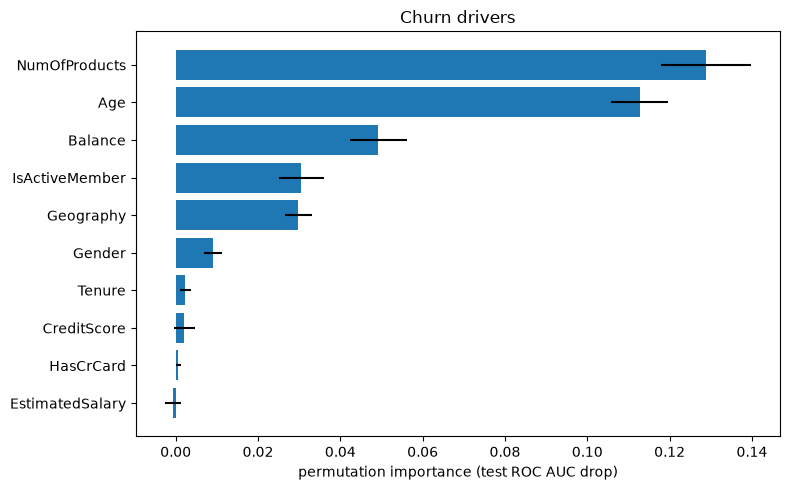

In [3]:
top = imp.iloc[::-1]
plt.figure(figsize=(8,5))
plt.barh(top['feature'], top['perm_importance'], xerr=top['perm_std'])
plt.xlabel('permutation importance (test ROC AUC drop)'); plt.title('Churn drivers')
plt.tight_layout(); plt.savefig(_root/'results'/'feature_importance.png',dpi=120); plt.show()

Churn is driven by **number of products**, **age**, **balance**, **activity**, and **geography**. Credit score, tenure, salary, and card ownership add almost nothing. A sensible, parsimonious story a retention team could act on. See `docs/learnings.md`.